## 1) Importación de librerías y configuración

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2) Carga y preparación de datos

In [2]:
df = pd.read_csv('Telco_Customer_Churn_Dataset.csv')

# Limpieza base (misma línea de trabajo de entregas previas)
df_model = df.copy()
df_model['TotalCharges'] = pd.to_numeric(df_model['TotalCharges'], errors='coerce')
df_model['TotalCharges'] = df_model['TotalCharges'].fillna(df_model['TotalCharges'].median())

if 'customerID' in df_model.columns:
    df_model = df_model.drop(columns=['customerID'])

print('Dimensiones:', df_model.shape)
display(df_model.head())

Dimensiones: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3) Parte A — Clasificación con GridSearchCV

**Target:** `Churn` (Yes=1, No=0).

In [3]:
# -------------------------
# Clasificación: datos
# -------------------------
df_clf = df_model.copy()
y_clf = df_clf['Churn'].map({'Yes': 1, 'No': 0})
X_clf_raw = df_clf.drop(columns=['Churn'])

cat_cols_clf = X_clf_raw.select_dtypes(include=['object']).columns
X_clf = pd.get_dummies(X_clf_raw, columns=cat_cols_clf, drop_first=True)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

num_cols = [c for c in ['tenure', 'MonthlyCharges', 'TotalCharges'] if c in Xc_train.columns]
scaler_clf = StandardScaler()
Xc_train_s = Xc_train.copy()
Xc_test_s = Xc_test.copy()
Xc_train_s[num_cols] = scaler_clf.fit_transform(Xc_train[num_cols])
Xc_test_s[num_cols] = scaler_clf.transform(Xc_test[num_cols])

# -------------------------
# Modelo base
# -------------------------
clf_base = LogisticRegression(max_iter=1500, random_state=RANDOM_STATE)
clf_base.fit(Xc_train_s, yc_train)
pred_base = clf_base.predict(Xc_test_s)
prob_base = clf_base.predict_proba(Xc_test_s)[:, 1]

base_metrics_clf = {
    'Modelo': 'Base - LogisticRegression',
    'F1': f1_score(yc_test, pred_base),
    'Precision': precision_score(yc_test, pred_base),
    'Recall': recall_score(yc_test, pred_base),
    'ROC_AUC': roc_auc_score(yc_test, prob_base)
}

# -------------------------
# GridSearchCV (cv=5)
# -------------------------
param_grid = {
    'n_estimators': [100, 200, 400],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample', None]
}

clf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=0
)
clf_grid.fit(Xc_train_s, yc_train)

clf_best = clf_grid.best_estimator_
pred_best = clf_best.predict(Xc_test_s)
prob_best = clf_best.predict_proba(Xc_test_s)[:, 1]

best_metrics_clf = {
    'Modelo': 'Optimizado - RF (GridSearchCV)',
    'F1': f1_score(yc_test, pred_best),
    'Precision': precision_score(yc_test, pred_best),
    'Recall': recall_score(yc_test, pred_best),
    'ROC_AUC': roc_auc_score(yc_test, prob_best)
}

df_cmp_clf = pd.DataFrame([base_metrics_clf, best_metrics_clf])
display(df_cmp_clf.style.format({'F1':'{:.4f}','Precision':'{:.4f}','Recall':'{:.4f}','ROC_AUC':'{:.4f}'}))

print('best_params_ clasificación:', clf_grid.best_params_)
print('best_score_ (CV F1) clasificación:', round(clf_grid.best_score_, 4))
print('\nReporte clasificación (modelo optimizado):')
print(classification_report(yc_test, pred_best))

,Modelo,F1,Precision,Recall,ROC_AUC
0,Base - LogisticRegression,0.6040,0.6572,0.5588,0.8421
1,Optimizado - RF (GridSearchCV),0.6304,0.5472,0.7433,0.8390


best_params_ clasificación: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
best_score_ (CV F1) clasificación: 0.642

Reporte clasificación (modelo optimizado):
              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1035
           1       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



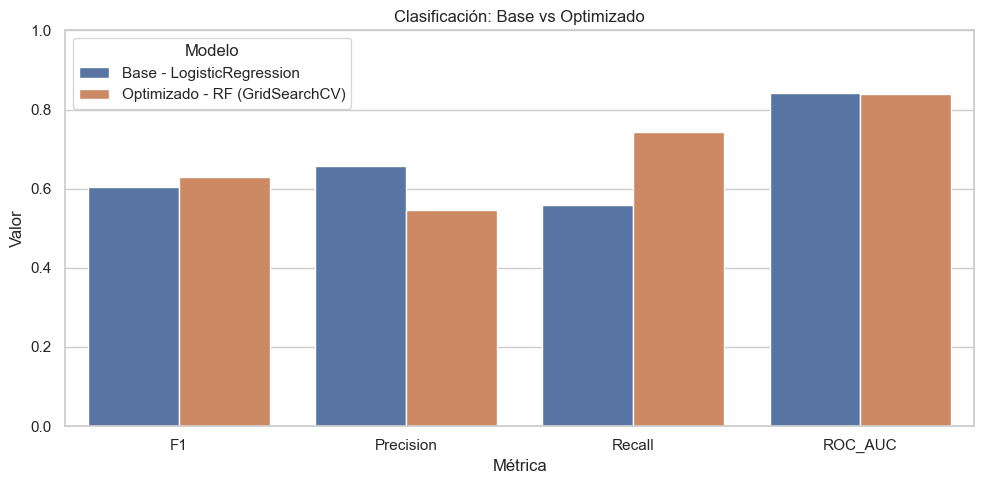

In [4]:
# Gráfico comparativo clasificación
plot_df_clf = df_cmp_clf.melt(id_vars='Modelo', value_vars=['F1','Precision','Recall','ROC_AUC'],
                          var_name='Métrica', value_name='Valor')

plt.figure(figsize=(10,5))
sns.barplot(data=plot_df_clf, x='Métrica', y='Valor', hue='Modelo')
plt.ylim(0, 1)
plt.title('Clasificación: Base vs Optimizado')
plt.tight_layout()
plt.show()

## 4) Parte B — Regresión con RandomizedSearchCV

**Target continuo:** `MonthlyCharges`.

In [9]:
# -------------------------
# Regresión: datos
# -------------------------
df_reg = df_model.copy()

y_reg = df_reg['MonthlyCharges']
X_reg_raw = df_reg.drop(columns=['MonthlyCharges'])

cat_cols_reg = X_reg_raw.select_dtypes(include=['object']).columns
X_reg = pd.get_dummies(X_reg_raw, columns=cat_cols_reg, drop_first=True)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

num_cols_reg = [c for c in ['tenure', 'TotalCharges'] if c in Xr_train.columns]
scaler_reg = StandardScaler()
Xr_train_s = Xr_train.copy()
Xr_test_s = Xr_test.copy()
Xr_train_s[num_cols_reg] = scaler_reg.fit_transform(Xr_train[num_cols_reg])
Xr_test_s[num_cols_reg] = scaler_reg.transform(Xr_test[num_cols_reg])

# -------------------------
# Modelo base
# -------------------------
reg_base = RandomForestRegressor(random_state=RANDOM_STATE)
reg_base.fit(Xr_train_s, yr_train)
pred_reg_base = reg_base.predict(Xr_test_s)

mae_base = mean_absolute_error(yr_test, pred_reg_base)
rmse_base = np.sqrt(mean_squared_error(yr_test, pred_reg_base))
r2_base = r2_score(yr_test, pred_reg_base)

# -------------------------
# RandomizedSearchCV (n_iter=20, cv=5)
# Métrica selección: neg_mean_squared_error
# -------------------------
param_dist = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 6],
    'max_features': ['sqrt', 'log2', None]
}

reg_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_mean_squared_error',
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)
reg_random.fit(Xr_train_s, yr_train)

reg_best = reg_random.best_estimator_
pred_reg_best = reg_best.predict(Xr_test_s)

mae_best = mean_absolute_error(yr_test, pred_reg_best)
rmse_best = np.sqrt(mean_squared_error(yr_test, pred_reg_best))
r2_best = r2_score(yr_test, pred_reg_best)

df_cmp_reg = pd.DataFrame([
    {'Modelo': 'Base - RF Regressor', 'MAE': mae_base, 'RMSE': rmse_base, 'R2': r2_base},
    {'Modelo': 'Optimizado - RF (RandomizedSearchCV)', 'MAE': mae_best, 'RMSE': rmse_best, 'R2': r2_best}
])

display(df_cmp_reg.style.format({'MAE':'{:.4f}','RMSE':'{:.4f}','R2':'{:.4f}'}))
print('best_params_ regresión:', reg_random.best_params_)
print('best_score_ (CV, neg MSE) regresión:', round(reg_random.best_score_, 4))

,Modelo,MAE,RMSE,R2
0,Base - RF Regressor,0.9133,1.2858,0.9982
1,Optimizado - RF (RandomizedSearchCV),0.9087,1.2803,0.9982


best_params_ regresión: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 20}
best_score_ (CV, neg MSE) regresión: -2.0219


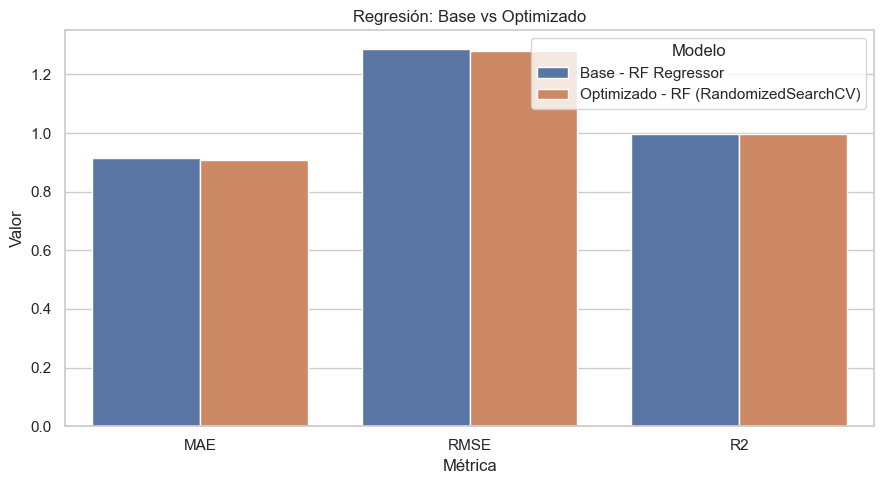

In [10]:
# Gráfico comparativo regresión
plot_df_reg = df_cmp_reg.melt(id_vars='Modelo', value_vars=['MAE','RMSE','R2'],
                          var_name='Métrica', value_name='Valor')

plt.figure(figsize=(9,5))
sns.barplot(data=plot_df_reg, x='Métrica', y='Valor', hue='Modelo')
plt.title('Regresión: Base vs Optimizado')
plt.tight_layout()
plt.show()

## 5) Análisis obligatorio (respuestas automáticas y guía)

In [11]:
# Cálculos para preguntas 7 y 8
n_combinaciones_grid = (len(param_grid['n_estimators']) *
                        len(param_grid['max_depth']) *
                        len(param_grid['min_samples_split']) *
                        len(param_grid['class_weight']))
entrenamientos_grid = n_combinaciones_grid * 5
entrenamientos_random = 20 * 5

print('1) Parámetro vs hiperparámetro:')
print('   - Parámetro: lo aprende el modelo durante entrenamiento (ej. coeficientes).')
print('   - Hiperparámetro: lo define el analista antes de entrenar (ej. n_estimators, max_depth).')

print('2) Mejor combinación (clasificación):', clf_grid.best_params_)
print(f"3) F1 base: {base_metrics_clf['F1']:.4f} | F1 optimizado: {best_metrics_clf['F1']:.4f}")

print('4) Efecto hiperparámetro (ejemplo max_depth):')
print('   - Profundidades bajas reducen sobreajuste pero pueden subajustar;')
print('   - profundidades altas mejoran ajuste en train pero pueden perder generalización.')

print('5) Mejor configuración (regresión):', reg_random.best_params_)
print(f"6) MAE base/opt: {mae_base:.4f}/{mae_best:.4f} | RMSE base/opt: {rmse_base:.4f}/{rmse_best:.4f} | R2 base/opt: {r2_base:.4f}/{r2_best:.4f}")

print(f'7) Entrenamientos GridSearchCV: {n_combinaciones_grid} combinaciones x 5 folds = {entrenamientos_grid}')
print(f'8) Entrenamientos RandomizedSearchCV: 20 iteraciones x 5 folds = {entrenamientos_random}')

print('9) Cuándo usar cada uno:')
print('   - GridSearchCV: espacio pequeño/mediano y necesidad de exploración exhaustiva.')
print('   - RandomizedSearchCV: espacio grande o presupuesto de tiempo limitado.')

print('10) Costo computacional:')
print('    - validar si la mejora de métricas en test compensa el tiempo adicional de búsqueda.')

1) Parámetro vs hiperparámetro:
   - Parámetro: lo aprende el modelo durante entrenamiento (ej. coeficientes).
   - Hiperparámetro: lo define el analista antes de entrenar (ej. n_estimators, max_depth).
2) Mejor combinación (clasificación): {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
3) F1 base: 0.6040 | F1 optimizado: 0.6304
4) Efecto hiperparámetro (ejemplo max_depth):
   - Profundidades bajas reducen sobreajuste pero pueden subajustar;
   - profundidades altas mejoran ajuste en train pero pueden perder generalización.
5) Mejor configuración (regresión): {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 20}
6) MAE base/opt: 0.9133/0.9087 | RMSE base/opt: 1.2858/1.2803 | R2 base/opt: 0.9982/0.9982
7) Entrenamientos GridSearchCV: 81 combinaciones x 5 folds = 405
8) Entrenamientos RandomizedSearchCV: 20 iteraciones x 5 folds = 100
9) Cuándo usar cada uno:
   - GridSearchCV: espacio peque

## 6) Conclusión final

En esta tercera entrega se evaluó el impacto de la optimización de hiperparámetros comparando modelos base vs optimizados con validación cruzada de 5 folds.

En **clasificación** (`Churn`), el modelo optimizado con `GridSearchCV` mejoró el desempeño global frente al baseline: el **F1** subió de **0.6040** a **0.6304**, y el **Recall** aumentó de **0.5588** a **0.7433**, lo que es especialmente útil para detectar más clientes con riesgo de fuga. La mejor configuración encontrada fue: `{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}`.

En **regresión** (`MonthlyCharges`), el modelo optimizado con `RandomizedSearchCV` mostró una mejora leve pero consistente: **MAE** pasó de **0.9133** a **0.9087**, **RMSE** de **1.2858** a **1.2803**, y **R²** se mantuvo en **0.9982**. La mejor configuración fue: `{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 20}`.

Respecto al costo computacional, `GridSearchCV` realizó **405 entrenamientos** (81 combinaciones × 5 folds), mientras que `RandomizedSearchCV` realizó **100 entrenamientos** (20 iteraciones × 5 folds). En este contexto, la optimización queda justificada sobre todo en clasificación, donde la ganancia fue más relevante para el objetivo del negocio.